# Predicción de Churn en un Banco

## Contexto
La entidad financiera tuvo una reducción del **15%** de clientes activos en el último trimestre. Para retenerlos diseñó un programa de beneficios (eliminación de cuota de manejo, mejores tasas, retiros ilimitados) y necesita **identificar qué clientes son más propensos a retirarse** para **priorizar** a quién ofrecerlos.

**Objetivo analítico:** Construir un modelo que estime la probabilidad de churn de cada cliente y usarlo para ordenar la campaña de retención.

## Metodología (CRISP-DM)
1. Entendimiento del negocio: problema del banco y objetivo del modelo (ver Contexto)
2. Entendimiento de los datos: calidad, variable objetivo y análisis exploratorio (EDA)
3. Preparación de datos: codificación, escalado, manejo del desbalance y partición train/test
4. Modelado: Optimización (descenso de gradiente), SVM, Redes Neuronales y Ensambles (Bagging, Random Forest, AdaBoost, Gradient Boosting, XGBoost)
5. Evaluación: comparación y selección del modelo, umbral de decisión e impacto de negocio con Simulación Montecarlo
6. Despliegue: priorización de clientes para la campaña de retención y recomendaciones de monitoreo

## 0. Configuración del notebook

In [1]:
%load_ext autoreload
%autoreload 2

Librerías y configuración de estilo y visualización.

In [2]:
import sys
from pathlib import Path

In [3]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

In [4]:
import pandas as pd
from IPython.display import display

from src import config as cfg
from src import viz
from src.data_understanding import eda, loading, quality

In [5]:
viz.set_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.3f}".format)

## 2. Entendimiento de los datos
### 2.1 Carga y diccionario de variables

In [6]:
df_raw = loading.load_raw()
print(f"Dimensiones: {df_raw.shape[0]:,} filas x {df_raw.shape[1]} columnas")
df_raw.head()

Dimensiones: 10,127 filas x 21 columnas


,clientnum,attrition_flag,customer_age,gender,dependent_count,education_level,marital_status,income_category,card_category,months_on_book,total_relationship_count,months_inactive_12_mon,contacts_count_12_mon,credit_limit,total_revolving_bal,avg_open_to_buy,total_amt_chng_q4_q1,total_trans_amt,total_trans_ct,total_ct_chng_q4_q1,avg_utilization_ratio
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,"12,691.000",777,"11,914.000",1.335,1144,42,1.625,0.061
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,"8,256.000",864,"7,392.000",1.541,1291,33,3.714,0.105
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,"3,418.000",0,"3,418.000",2.594,1887,20,2.333,0.000
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,3,4,1,"3,313.000",2517,796.000,1.405,1171,20,2.333,0.760
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,"4,716.000",0,"4,716.000",2.175,816,28,2.500,0.000


In [3]:
quality.data_dictionary(df_raw)

,descripcion,tipo,nulos,unicos,ejemplo
variable,,,,,
clientnum,Identificador único del cliente,int64,0,10127,768805383
attrition_flag,Variable objetivo: el cliente se fue a otro ba...,str,0,2,Existing Customer
customer_age,Edad del cliente,int64,0,45,45
gender,Sexo del cliente,str,0,2,M
dependent_count,Número de personas económicamente dependientes,int64,0,6,3
education_level,Nivel educativo,str,0,7,High School
marital_status,Estado civil,str,0,4,Married
income_category,Categoría de ingresos,str,0,6,$60K - $80K
card_category,Categoría de tarjeta,str,0,4,Blue


### 2.2 Calidad de los datos

In [7]:
quality.quality_report(df_raw).to_frame()

,valor
filas,10127
columnas,21
celdas nulas,0
filas duplicadas,0
clientnum único,True
celdas 'Unknown',3380
filas con algún 'Unknown',3046
% filas con 'Unknown',30.080


In [8]:
df = loading.load_data()

In [15]:
df.head(5)

,customer_age,gender,dependent_count,education_level,marital_status,income_category,card_category,months_on_book,total_relationship_count,months_inactive_12_mon,contacts_count_12_mon,credit_limit,total_revolving_bal,avg_open_to_buy,total_amt_chng_q4_q1,total_trans_amt,total_trans_ct,total_ct_chng_q4_q1,avg_utilization_ratio,churn
clientnum,,,,,,,,,,,,,,,,,,,,
768805383,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,"12,691.000",777,"11,914.000",1.335,1144,42,1.625,0.061,0
818770008,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,"8,256.000",864,"7,392.000",1.541,1291,33,3.714,0.105,0
713982108,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,"3,418.000",0,"3,418.000",2.594,1887,20,2.333,0.000,0
769911858,40,F,4,High School,Unknown,Less than $40K,Blue,34,3,4,1,"3,313.000",2517,796.000,1.405,1171,20,2.333,0.760,0
709106358,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,"4,716.000",0,"4,716.000",2.175,816,28,2.500,0.000,0


In [9]:
quality.unknown_summary(df)

,n_unknown,% registros,churn % (Unknown),churn % (resto)
variable,,,,
education_level,1519,15.000,16.850,15.930
marital_status,749,7.400,17.220,15.970
income_category,1112,10.980,16.820,15.970


### 2.3 Variable objetivo

,n,%
clase,,
Existing (0),8500,83.930
Attrited (1),1627,16.070


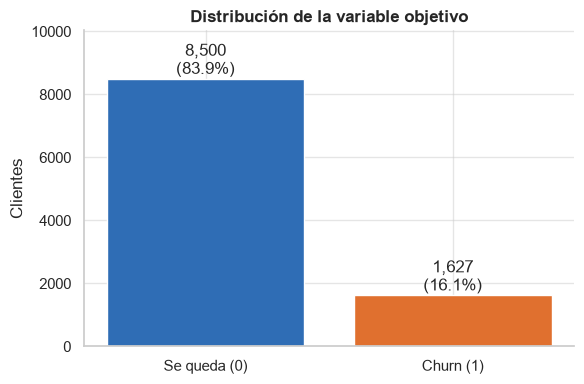

In [10]:
display(quality.target_distribution(df))
fig = eda.plot_target(df)
viz.save_fig(fig, "01_target_distribution")

### 2.4 Estadísticas descriptivas

In [11]:
df[cfg.NUMERIC_COLS].describe().T

,count,mean,std,min,25%,50%,75%,max
customer_age,"10,127.000",46.326,8.017,26.000,41.000,46.000,52.000,73.000
dependent_count,"10,127.000",2.346,1.299,0.000,1.000,2.000,3.000,5.000
months_on_book,"10,127.000",35.928,7.986,13.000,31.000,36.000,40.000,56.000
total_relationship_count,"10,127.000",3.813,1.554,1.000,3.000,4.000,5.000,6.000
months_inactive_12_mon,"10,127.000",2.341,1.011,0.000,2.000,2.000,3.000,6.000
contacts_count_12_mon,"10,127.000",2.455,1.106,0.000,2.000,2.000,3.000,6.000
credit_limit,"10,127.000","8,631.954","9,088.777","1,438.300","2,555.000","4,549.000","11,067.500","34,516.000"
total_revolving_bal,"10,127.000","1,162.814",814.987,0.000,359.000,"1,276.000","1,784.000","2,517.000"
avg_open_to_buy,"10,127.000","7,469.140","9,090.685",3.000,"1,324.500","3,474.000","9,859.000","34,516.000"
total_amt_chng_q4_q1,"10,127.000",0.760,0.219,0.000,0.631,0.736,0.859,3.397


In [13]:
  for col in cfg.CATEGORICAL_COLS:
    display(quality.categorical_frequencies(df, col))

,n,%
gender,,
F,5358,52.910
M,4769,47.090


,n,%
education_level,,
Uneducated,1487,14.680
High School,2013,19.880
College,1013,10.000
Graduate,3128,30.890
Post-Graduate,516,5.100
Doctorate,451,4.450
Unknown,1519,15.000


,n,%
marital_status,,
Married,4687,46.280
Single,3943,38.940
Unknown,749,7.400
Divorced,748,7.390


,n,%
income_category,,
Less than $40K,3561,35.160
$40K - $60K,1790,17.680
$60K - $80K,1402,13.840
$80K - $120K,1535,15.160
$120K +,727,7.180
Unknown,1112,10.980


,n,%
card_category,,
Blue,9436,93.180
Silver,555,5.480
Gold,116,1.150
Platinum,20,0.200


### Conclusiones: entendimiento de los datos

- **Base limpia a nivel técnico:** 10.127 clientes, 21 variables, sin valores nulos ni filas duplicadas; `clientnum` es único y se usa solo como índice (no es predictor).
- **Datos faltantes:** `education_level` (15,0%), `income_category` (11,0%) y `marital_status` (7,4%) usan la categoría **"Unknown"**. No son nulos explícitos, pero sí información faltante. La tasa de churn en esos registros es similar a la del resto, por lo que se trabajarán como **categoría propia** en lugar de eliminarlos (se perdería cerca del 30% de la base).
- **Desbalance de clases:** solo el **16,1%** de los clientes hizo churn (1.627 vs 8.500). Un modelo que prediga "nadie se va" tendría 84% de accuracy y sería inútil, así que la **accuracy no sirve como métrica principal**: usaremos Recall, Precision, F1, ROC-AUC y sobre todo PR-AUC de la clase churn, además de técnicas para el desbalance (pesos de clase, SMOTE, ajuste de umbral).
- **`card_category` muy concentrada:** 93% de los clientes tiene tarjeta Blue; Gold y Platinum tienen pocos casos (116 y 20), lo que limita su poder explicativo.
- Las escalas de las variables numéricas son muy distintas (p. ej. `credit_limit` llega a 34.516 y `avg_utilization_ratio` está entre 0 y 1), por lo que **SVM, redes neuronales y la logística por gradiente necesitarán escalado**.

### 2.5 Análisis exploratorio: variables numéricas

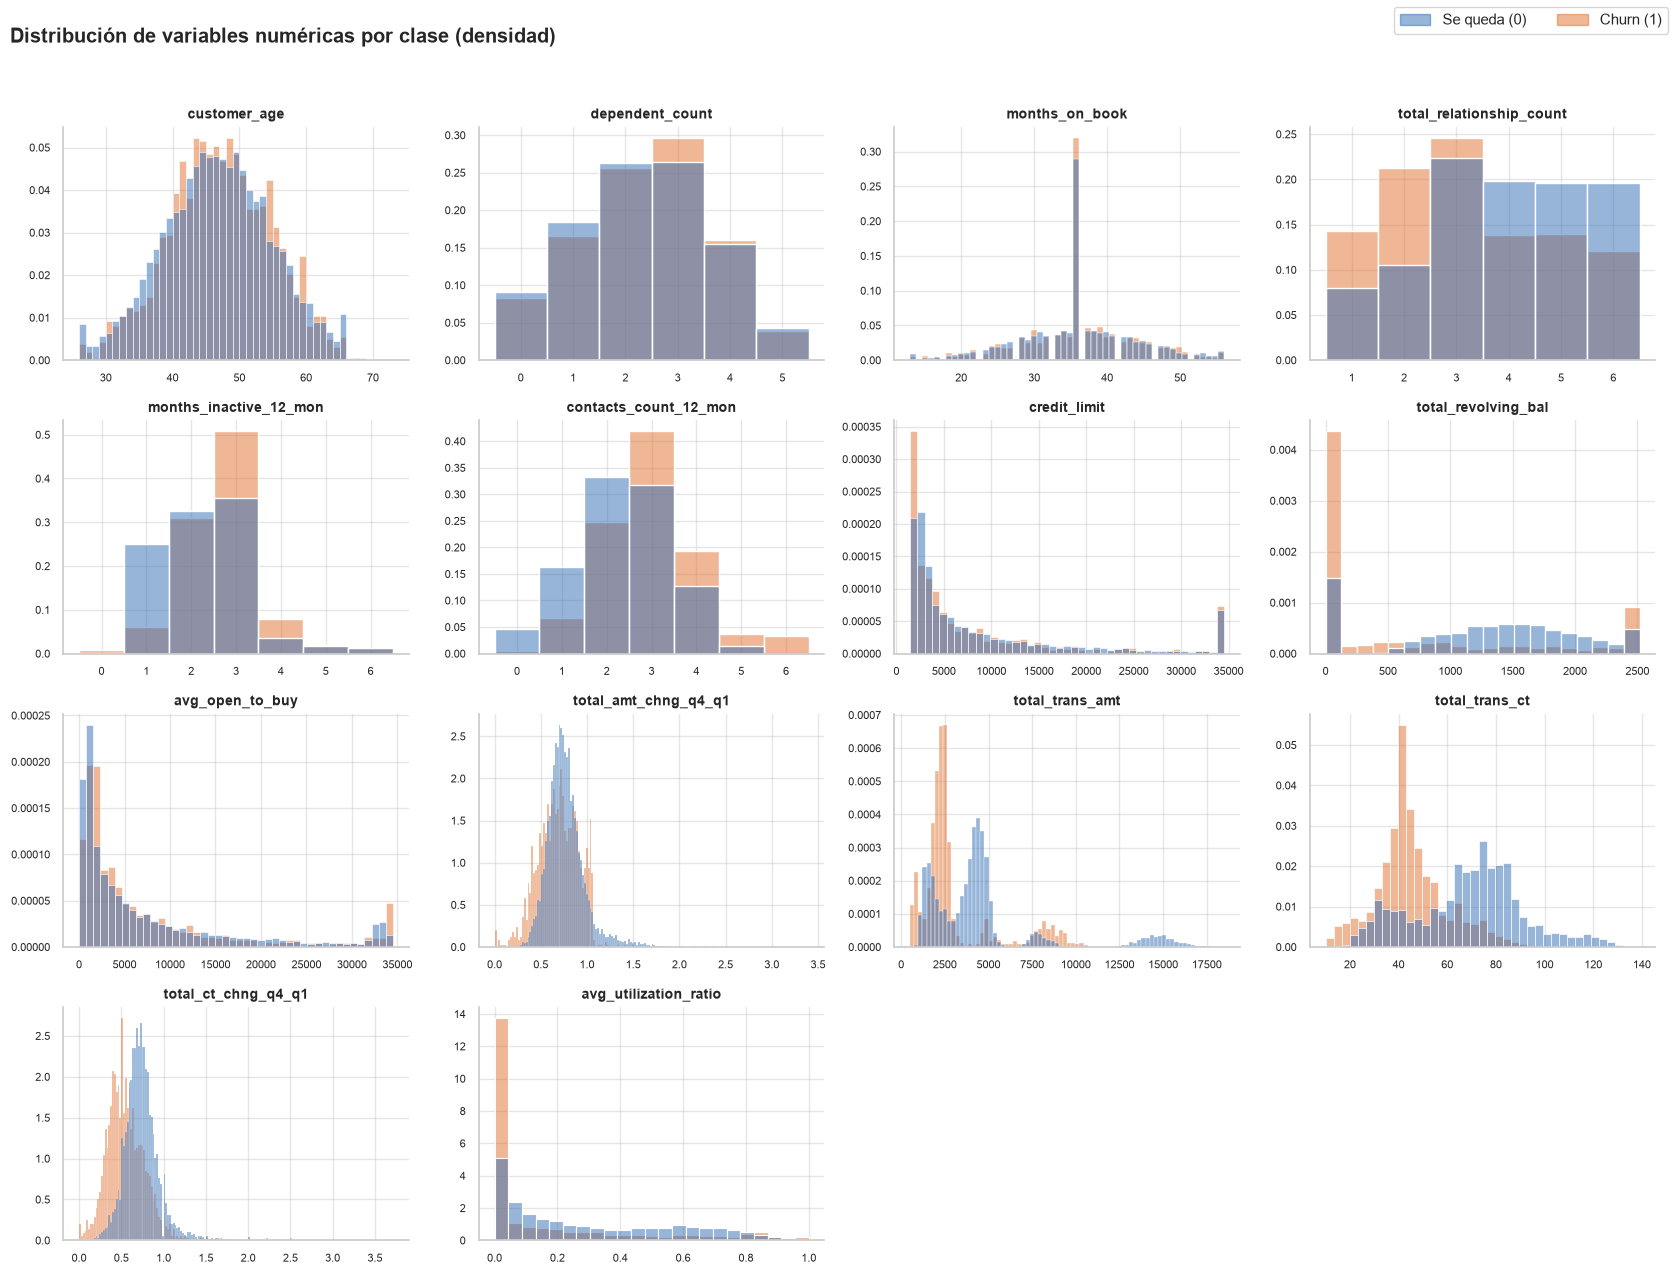

In [14]:
fig = eda.plot_numeric_distributions(df)
viz.save_fig(fig, "02_numeric_distributions")

In [16]:
eda.numeric_medians_by_class(df)

,mediana se queda (0),mediana churn (1),dif %
total_revolving_bal,"1,364.000",0.000,-100.000
avg_utilization_ratio,0.211,0.000,-100.000
months_inactive_12_mon,2.000,3.000,50.000
contacts_count_12_mon,2.000,3.000,50.000
total_trans_amt,"4,100.000","2,329.000",-43.200
total_trans_ct,71.000,43.000,-39.400
total_ct_chng_q4_q1,0.721,0.531,-26.400
total_relationship_count,4.000,3.000,-25.000
credit_limit,"4,643.500","4,178.000",-10.000
total_amt_chng_q4_q1,0.743,0.701,-5.700


In [17]:
for col, table in eda.churn_rate_by_discrete_values(df).items():
    display(table)

,clientes,churn %
dependent_count,,
0,904,14.900
1,1838,14.600
2,2655,15.700
3,2732,17.600
4,1574,16.500
5,424,15.100


,clientes,churn %
total_relationship_count,,
1,910,25.600
2,1243,27.800
3,2305,17.400
4,1912,11.800
5,1891,12.000
6,1866,10.500


,clientes,churn %
months_inactive_12_mon,,
0,29,51.700
1,2233,4.500
2,3282,15.400
3,3846,21.500
4,435,29.900
5,178,18.000
6,124,15.300


,clientes,churn %
contacts_count_12_mon,,
0,399,1.800
1,1499,7.200
2,3227,12.500
3,3380,20.100
4,1392,22.600
5,176,33.500
6,54,100.000


In [18]:
eda.numeric_findings(df).to_frame()

,valor
% churn con balance rotativo = 0,54.900
% no churn con balance rotativo = 0,18.600
clientes con total_trans_amt > 11.000,747
churn % con total_trans_amt > 11.000,0.000
% clientes con months_on_book = 36 (moda),24.300
"% clientes con credit_limit = máximo (34,516)",5.000
correlación credit_limit vs avg_open_to_buy,0.996


**Variables que más diferencian a los clientes que se van (actividad transaccional):**
- `total_trans_ct`: la mediana de transacciones de los clientes con churn es **43**, frente a **71** de los que se quedan.
- `total_trans_amt`: mediana de **2.329** frente a **4.100**. Ninguno de los 747 clientes con monto mayor a 11.000 hizo churn.
- `total_ct_chng_q4_q1`: los que se van tienen una caída más fuerte de transacciones entre Q4 y Q1 (mediana **0,53** frente a **0,72**).
- `total_revolving_bal` y `avg_utilization_ratio`: el **55%** de los clientes con churn tiene balance rotativo en 0, frente al **19%** de los que se quedan. Quien no usa la tarjeta tiene menos vínculo con el banco.

**Variables de relación con el banco:**
- `total_relationship_count`: a menos productos, más churn. Con 1 o 2 productos la tasa de churn es del 26% al 28%; con 4 o más baja a cerca del 11%.
- `months_inactive_12_mon`: la tasa de churn sube de 4,5% (1 mes inactivo) a 30% (4 meses inactivo).
- `contacts_count_12_mon`: la tasa de churn crece con cada contacto, de 1,8% (0 contactos) a 33,5% (5 contactos), y los **54 clientes con 6 contactos se fueron todos**. Los contactos parecen reflejar reclamos o problemas, no gestión comercial.

**Variables que casi no diferencian:** `customer_age`, `dependent_count`, `months_on_book`, `credit_limit` y `avg_open_to_buy` tienen distribuciones muy parecidas en ambas clases.

**Hallazgos de calidad de datos:**
- `months_on_book` tiene un pico anormal en **36 meses (24,3% de los clientes)**. Puede tratarse de un valor por defecto.
- `credit_limit` se acumula en el máximo de **34.516** (5% de los clientes), tal vez un tope del producto.
- `credit_limit` y `avg_open_to_buy` tienen una correlación de **0,996**: son casi la misma información.
- Hay 29 clientes con 0 meses de inactividad y un churn del 52%; es un grupo muy pequeño, así que no se saca conclusión sobre él.

**Lectura de negocio:** el cliente que se va **ya venía desconectándose**: transacciona menos, reduce su actividad entre trimestres, no usa el crédito rotativo, tiene pocos productos y contacta más al banco. Son señales que el banco observa **antes** del retiro, lo que permite anticiparse con la campaña de beneficios.

### 2.6 Análisis exploratorio: variables categóricas
Para cada categoría se calcula la **tasa de churn**. La línea punteada es la tasa general: las barras naranjas están por encima y las azules por debajo. El `n` sobre cada barra indica cuántos clientes hay en la categoría

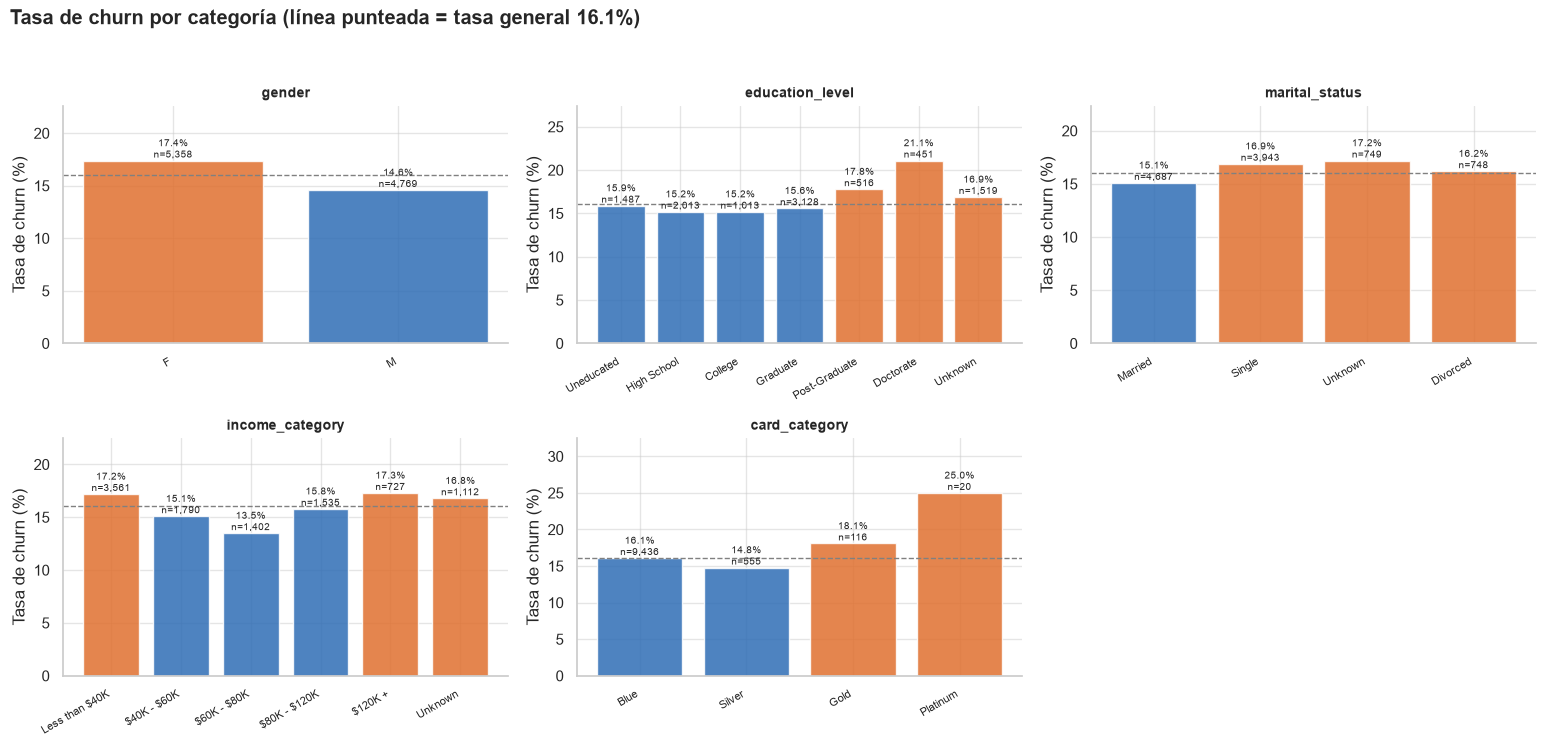

In [22]:
fig = eda.plot_categorical_churn_rate(df)
viz.save_fig(fig, "03_categorical_churn_rate")


In [23]:
for col, table in eda.churn_rate_by_categorical(df).items():
    display(table)

,clientes,churn %
gender,,
F,5358,17.400
M,4769,14.600


,clientes,churn %
education_level,,
Uneducated,1487,15.900
High School,2013,15.200
College,1013,15.200
Graduate,3128,15.600
Post-Graduate,516,17.800
Doctorate,451,21.100
Unknown,1519,16.900


,clientes,churn %
marital_status,,
Married,4687,15.100
Single,3943,16.900
Unknown,749,17.200
Divorced,748,16.200


,clientes,churn %
income_category,,
Less than $40K,3561,17.200
$40K - $60K,1790,15.100
$60K - $80K,1402,13.500
$80K - $120K,1535,15.800
$120K +,727,17.300
Unknown,1112,16.800


,clientes,churn %
card_category,,
Blue,9436,16.100
Silver,555,14.800
Gold,116,18.100
Platinum,20,25.000


#### Prueba chi-cuadrado de independencia
¿Las diferencias en la tasa de churn entre categorías son reales o pueden deberse al azar?

- **H0:** la tasa de churn es la misma en todas las categorías (la variable no está relacionada con el churn).
- **H1:** la tasa de churn depende de la categoría.
- Si el **p-valor < 0,05** se rechaza H0: la variable sí está relacionada con el churn.
- La **V de Cramér** mide la fuerza de la relación (0 = ninguna, 1 = total). Con 10.127 clientes, hasta diferencias pequeñas resultan significativas, así que hay que mirar las dos cosas: si la relación existe (p-valor) y qué tan fuerte es (V de Cramér). Como referencia, V < 0,1 se considera una relación débil.
- **Supuesto:** la prueba es confiable cuando todas las frecuencias esperadas son de al menos 5 (columna `min. esperado`).

In [24]:
eda.chi2_tests(df)

,chi2,gl,p-valor,significativa (p<0.05),V de Cramér,min. esperado
variable,,,,,,
gender,13.870,1,0.000,Sí,0.037,766.200
income_category,12.830,5,0.025,Sí,0.036,116.800
education_level,12.510,6,0.051,No,0.035,72.500
marital_status,6.060,3,0.109,No,0.024,120.200
card_category,2.230,3,0.525,No,0.015,3.200


- `gender`: las mujeres se van más que los hombres (**17,4%** vs **14,6%**). Es la relación más significativa entre las categóricas (p = 0,0002).
- `income_category`: Los extremos están por encima del promedio y el rango $60K - $80K es el más bajo. Es significativa (p = 0,025).
- `education_level`: los niveles más altos se van más (Post-Graduate **17,8%**, Doctorate **21,1%**), pero en conjunto la variable queda en el límite de la significancia (p = 0,051).
- `marital_status`: los casados se van un poco menos (**15,1%**) que los solteros (**16,9%**); la diferencia no es significativa (p = 0,109).
- `card_category`: Platinum muestra **25%** de churn, pero son solo **20 clientes**; la prueba no es significativa (p = 0,525).
- La categoría "Unknown" tiene tasas cercanas al promedio en las tres variables donde aparece, lo que confirma la decisión de mantenerla como una categoría más.

**Fuerza de la relación:** aunque género e ingreso son significativos, **todas las V de Cramér son menores a 0,04**, es decir, relaciones muy débiles. Con más de 10.000 clientes, diferencias de 2 o 3 puntos resultan estadísticamente significativas, pero tienen poco poder para separar a quien se va de quien se queda.

El churn se explica por lo que el cliente hace (transacciones, productos, inactividad, contactos) mucho más que por quién es (género, educación, estado civil, ingresos, tipo de tarjeta). Una campaña segmentada solo por perfil demográfico sería poco efectiva; la priorización debe basarse en variables de comportamiento. Las variables demográficas se mantienen en el modelado porque pueden aportar en combinación con las demás.

### 2.7 Correlación entre variables numéricas
Se usa la correlación de **Spearman** (por rangos) en lugar de Pearson, porque varias variables son asimétricas o tienen muchos ceros. Spearman es robusta a valores extremos y capta relaciones monótonas aunque no sean lineales. Va de -1 a 1: rojo = relación positiva, azul = negativa, blanco = sin relación.

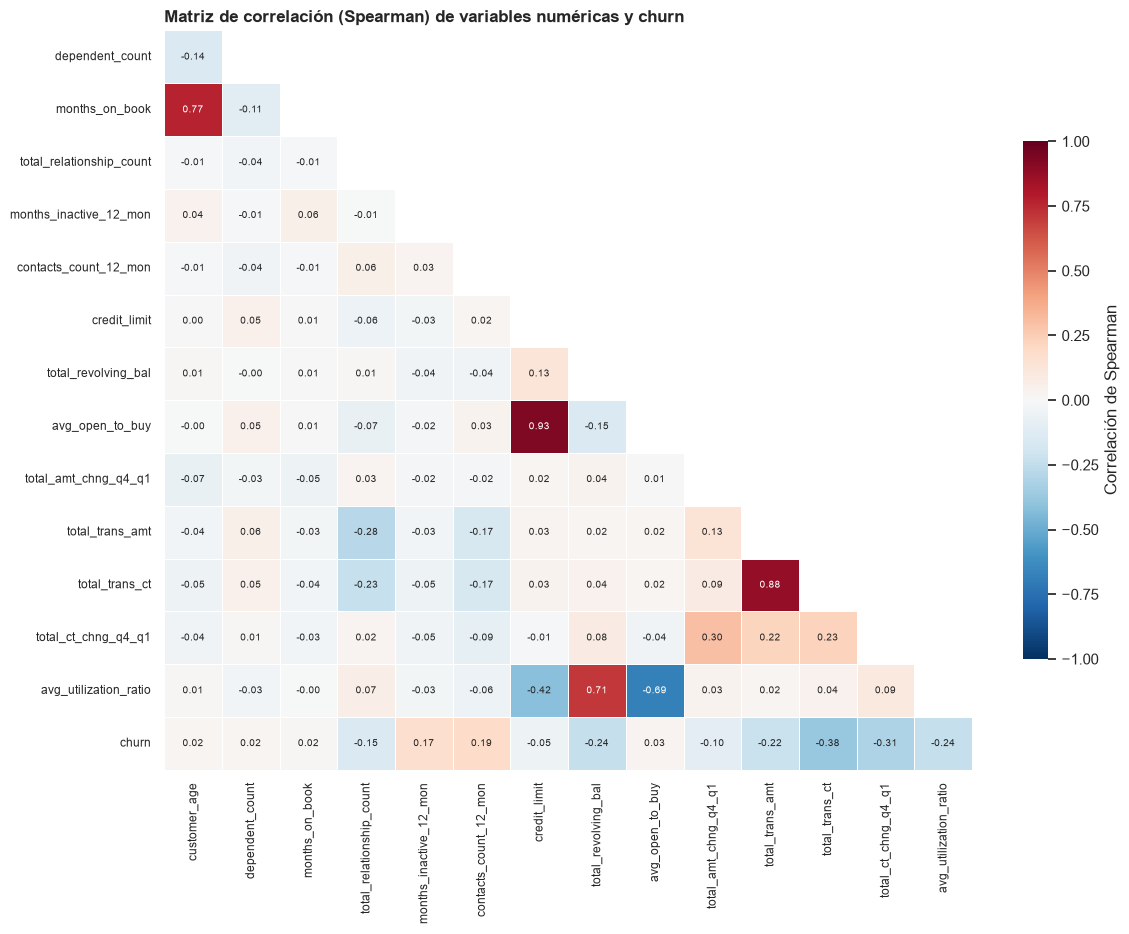

In [25]:
fig = eda.plot_correlation_matrix(df)
viz.save_fig(fig, "04_correlation_matrix")

In [26]:
eda.high_correlation_pairs(df, threshold=0.7)

,variable 1,variable 2,correlación
0,credit_limit,avg_open_to_buy,0.931
1,total_trans_amt,total_trans_ct,0.880
2,customer_age,months_on_book,0.769
3,total_revolving_bal,avg_utilization_ratio,0.709


In [27]:
eda.correlation_with_target(df)

,correlación con churn (spearman)
total_trans_ct,-0.376
total_ct_chng_q4_q1,-0.312
total_revolving_bal,-0.241
avg_utilization_ratio,-0.240
total_trans_amt,-0.224
contacts_count_12_mon,0.189
months_inactive_12_mon,0.172
total_relationship_count,-0.150
total_amt_chng_q4_q1,-0.102
credit_limit,-0.051


In [29]:
eda.derived_variable_checks(df)

,tolerancia,% clientes que la cumplen,máxima diferencia
identidad,,,
avg_open_to_buy = credit_limit - total_revolving_bal,1.000,100.000,0.000
avg_utilization_ratio = total_revolving_bal / credit_limit,0.001,100.000,0.001


**Variables redundantes (|r| ≥ 0,7):**

| Par | Spearman | Explicación | Decisión a evaluar en la Fase 3 |
|---|---|---|---|
| `credit_limit` y `avg_open_to_buy` | 0,93 | `avg_open_to_buy` es **exactamente** `credit_limit - total_revolving_bal` en el 100% de los clientes. No aporta información nueva. | Eliminar `avg_open_to_buy`. |
| `total_trans_amt` y `total_trans_ct` | 0,88 | Quien hace más transacciones mueve más dinero. No son un cálculo una de otra y las dos están entre los mejores predictores. | Mantener ambas y evaluar una variable de **ticket promedio** (`total_trans_amt / total_trans_ct`). |
| `customer_age` y `months_on_book` | 0,77 | Los clientes mayores llevan más tiempo en el banco. Ninguna de las dos se relaciona con el churn (correlación cercana a 0). | Mantener; los modelos con regularización y los ensambles decidirán su peso. |
| `total_revolving_bal` y `avg_utilization_ratio` | 0,71 | `avg_utilization_ratio` es **exactamente** `total_revolving_bal / credit_limit` (redondeada a 3 decimales). Es una relación no lineal, así que la razón sí puede aportar a modelos lineales. | Comparar el desempeño con y sin la razón. |

La redundancia afecta sobre todo a los modelos lineales (regresión logística y SVM lineal): los coeficientes se vuelven inestables y difíciles de interpretar. Los árboles y ensambles se ven poco afectados en desempeño, pero reparten la importancia entre las variables redundantes, lo que confunde la interpretación.

### 2.8 Prueba de Mann-Whitney: ¿las variables numéricas difieren entre clases?
Es el equivalente del chi-cuadrado para las variables numéricas.

- **H0:** la variable tiene la misma distribución en los clientes que se van y en los que se quedan.
- **H1:** las distribuciones son distintas.
- Se usa **Mann-Whitney** y no la prueba t porque varias variables no son normales (asimetrías, muchos ceros). Mann-Whitney no asume normalidad: compara rangos.
- **Tamaño del efecto (r, correlación biserial de rangos):** va de -1 a 1. r < 0 significa que los churners tienen valores **más bajos**; r > 0, **más altos**. Convención: |r| < 0,1 despreciable, < 0,3 pequeño, < 0,5 mediano, ≥ 0,5 grande. Igual que con la V de Cramér, con más de 10.000 clientes casi todo resulta significativo, por eso el tamaño del efecto es lo que indica qué tan útil es la variable.

In [30]:
eda.mann_whitney_tests(df)

,U,p-valor,significativa (p<0.05),efecto r,magnitud
variable,,,,,
total_trans_ct,2826174,<0.0001,Sí,-0.591,grande
total_ct_chng_q4_q1,3522217,<0.0001,Sí,-0.491,mediano
total_revolving_bal,4318784,<0.0001,Sí,-0.375,mediano
avg_utilization_ratio,4320406,<0.0001,Sí,-0.375,mediano
total_trans_amt,4481880,<0.0001,Sí,-0.352,mediano
contacts_count_12_mon,8890849,<0.0001,Sí,0.286,pequeño
months_inactive_12_mon,8687418,<0.0001,Sí,0.256,pequeño
total_relationship_count,5315342,<0.0001,Sí,-0.231,pequeño
total_amt_chng_q4_q1,5806261,<0.0001,Sí,-0.160,pequeño


- **Efecto grande:** `total_trans_ct` (r = **-0,59**) es la variable que más separa a las dos clases: los churners hacen muchas menos transacciones.
- **Efecto mediano:** `total_ct_chng_q4_q1` (**-0,49**), `total_revolving_bal` y `avg_utilization_ratio` (**-0,375** cada una, coinciden porque una es cálculo de la otra) y `total_trans_amt` (**-0,35**).
- **Efecto pequeño:** `contacts_count_12_mon` (**0,29**) y `months_inactive_12_mon` (**0,26**), con signo positivo: los churners tienen más contactos y más inactividad. También `total_relationship_count` (**-0,23**) y `total_amt_chng_q4_q1` (**-0,16**).
- **Efecto despreciable:** `credit_limit`, `avg_open_to_buy` y `dependent_count` son significativas (p < 0,05) pero con |r| < 0,1, es decir, la diferencia existe pero es irrelevante en la práctica. `customer_age` (p = 0,078) y `months_on_book` (p = 0,124) ni siquiera son significativas.

### Conclusiones análisis exploratorio

**1. Perfil del cliente que se va: se desconecta antes de irse.**
Comparado con el que se queda, el cliente que hace churn:
- Hace muchas menos transacciones y mueve menos dinero
- Reduce su actividad entre Q4 y Q1 más que el resto
- No usa el crédito rotativo
- Tiene menos productos con el banco

**2. El comportamiento pesa mucho más que el perfil demográfico.**
- Las variables de actividad tienen efectos grandes o medianos
- Las demográficas tienen relaciones muy débiles

**3. Decisiones**
- **Eliminar `avg_open_to_buy`:** es exactamente `credit_limit - total_revolving_bal`.
- **Evaluar `avg_utilization_ratio`:** es exactamente `total_revolving_bal / credit_limit`; comparar el modelo con y sin ella.
- **Mantener "Unknown" como una categoría más:** su tasa de churn es similar a la del resto y eliminarla haría perder cerca del 30% de la base.
- **Manejar el desbalance** (16,1% de churn): pesos de clase, SMOTE y ajuste del umbral de decisión, evaluando con métricas adecuadas (Recall, PR-AUC) y no con accuracy.